# Figure 4 — QTL–GWAS colocalization and rare-variant TWAS


This notebook reproduces **Figure 4**. The figure connects molecular QTL
colocalization with GWAS traits to downstream rare-variant signal: how many genes
colocalize per trait category and at what lenient credible-set rate, the R² that
rare variants add to TWAS, whether colocalized genes carry inflated conditional-TWAS
signal versus matched controls, and whether that signal enriches in clinically
important gene sets.

Like Figure 3, `00_setup.R` provides **memoized derived-data builders**
(`read_conditional_twas()`, `gene_sets()`, `coloc_by_trait()`,
`qq_match_source()`, `gene_twas_data()`) that each build once and cache to
`Fig4/data/`. Panels call only the builders they need.


## How to run

* **Kernel:** R (IRkernel). **Working directory:** the repository root (the folder that contains `Fig4/`).
* Run the cells top to bottom. Each panel caches its ggplot object to `Fig4/objects/`, and the assembly cell reads those back.
* Re-running a single panel cell rebuilds just that panel; re-run the assembly cell to recompose.


### Inputs

> **Controlled-access.** Every input derives from *All of Us* controlled-access
> data and is not in this repository; run this on the Workbench.

Inputs are **manifest-driven** (`Fig4/inputs.tsv`). The two
`high_level_coloc_outputs/` tables are extracted from a single archive
(`gsutil cp gs://…/high_level_coloc_outputs.tar.gz . && tar -xf …`); the ClinGen
parquet, drug-interaction table, R² and conditional-TWAS tables are local-only and
must be pre-staged. The derived-data builders cache to `Fig4/data/` **by name**,
so clear that directory (or pass `refresh = TRUE`) after changing an input.

> **Results differ from the pre-cleanup script.** The duplicated
> conditional-TWAS table (Panel D) is deduplicated to its clean version, and the
> unused GeneBayes read is dropped. See `Fig4/NOTES.md`.


## Setup

`00_setup.R` is the shared foundation every step builds on: it loads the libraries, sets the **Inter** font with a matched output **DPI**, defines the `theme_set`/`SZ_*` design system and the env-overridable paths, and brings in the manifest loaders and the folded-in analysis / plot functions plus the memoized derived-data builders — so the figure is self-contained.


In [1]:
## Locate the figure directory. Terra / Linux is case-sensitive, so match
## either "Fig4" or "fig4" and point the pipeline's env-overridable
## paths at it before sourcing the shared setup.
fig_dir <- list.files(".", pattern = "^(Fig4|fig4)$", include.dirs = TRUE)
stopifnot("Run this notebook from the repository root (the folder holding Fig4/)." =
          length(fig_dir) == 1)
Sys.setenv(FIG4_MANIFEST = file.path(fig_dir, "inputs.tsv"),
           FIG4_OBJ = file.path(fig_dir, "objects"),
           FIG4_DATA = file.path(fig_dir, "data"))
source(file.path(fig_dir, "00_setup.R"))

## Inline rendering. The canvas resolution is matched to DPI because 00_setup.R
## pins showtext to it (showtext_opts(dpi = DPI)); if the two disagree, every
## label renders at the wrong size. Panels display at a readable default, and
## the assemble cell overrides these with the composed figure's true aspect.
options(repr.plot.width = 7.5, repr.plot.height = 5, repr.plot.res = DPI)
cat("Setup loaded from", fig_dir, "\n")


Warning message:
“package ‘ggplot2’ was built under R version 4.3.3”


Warning message:
“package ‘patchwork’ was built under R version 4.3.3”


Warning message:
“package ‘ggh4x’ was built under R version 4.3.3”


Warning message:
“package ‘MatchIt’ was built under R version 4.3.3”


Warning message:
“package ‘arrow’ was built under R version 4.3.3”


Warning message:
“package ‘scales’ was built under R version 4.3.3”


Warning message:
“package ‘showtext’ was built under R version 4.3.3”


Warning message:
“package ‘sysfonts’ was built under R version 4.3.3”


Warning message:
“package ‘showtextdb’ was built under R version 4.3.3”


Setup loaded from Fig4 


### Panels

Each panel below **loads only the inputs it needs** (staging them on demand), does its wrangling, builds one ggplot object, caches it to `Fig4/objects/`, and renders it inline.


### Panel A — colocalizing-gene counts + credible-set coloc rate, by trait category

For each trait category, the number of colocalizing genes (intensity-shaded bars) beside the credible-set colocalization rate (lollipop, with a dashed median reference). The rate plotted is the **lenient** union rate (`pct_lenient_union`): `coloc_by_trait()` calls `build_plot_data(rate_type = "lenient")`, even though that function's own default is `"stringent"` — a caller reusing it gets the stringent rate unless it asks otherwise. The panel keeps **traits** with more than five colocalizing genes, then the top ten traits *within each category*, and drops the `neuropsychiatric` and `renal_urological` categories.

*Inputs: coloc_gene, coloc_rate*


Panel A built.



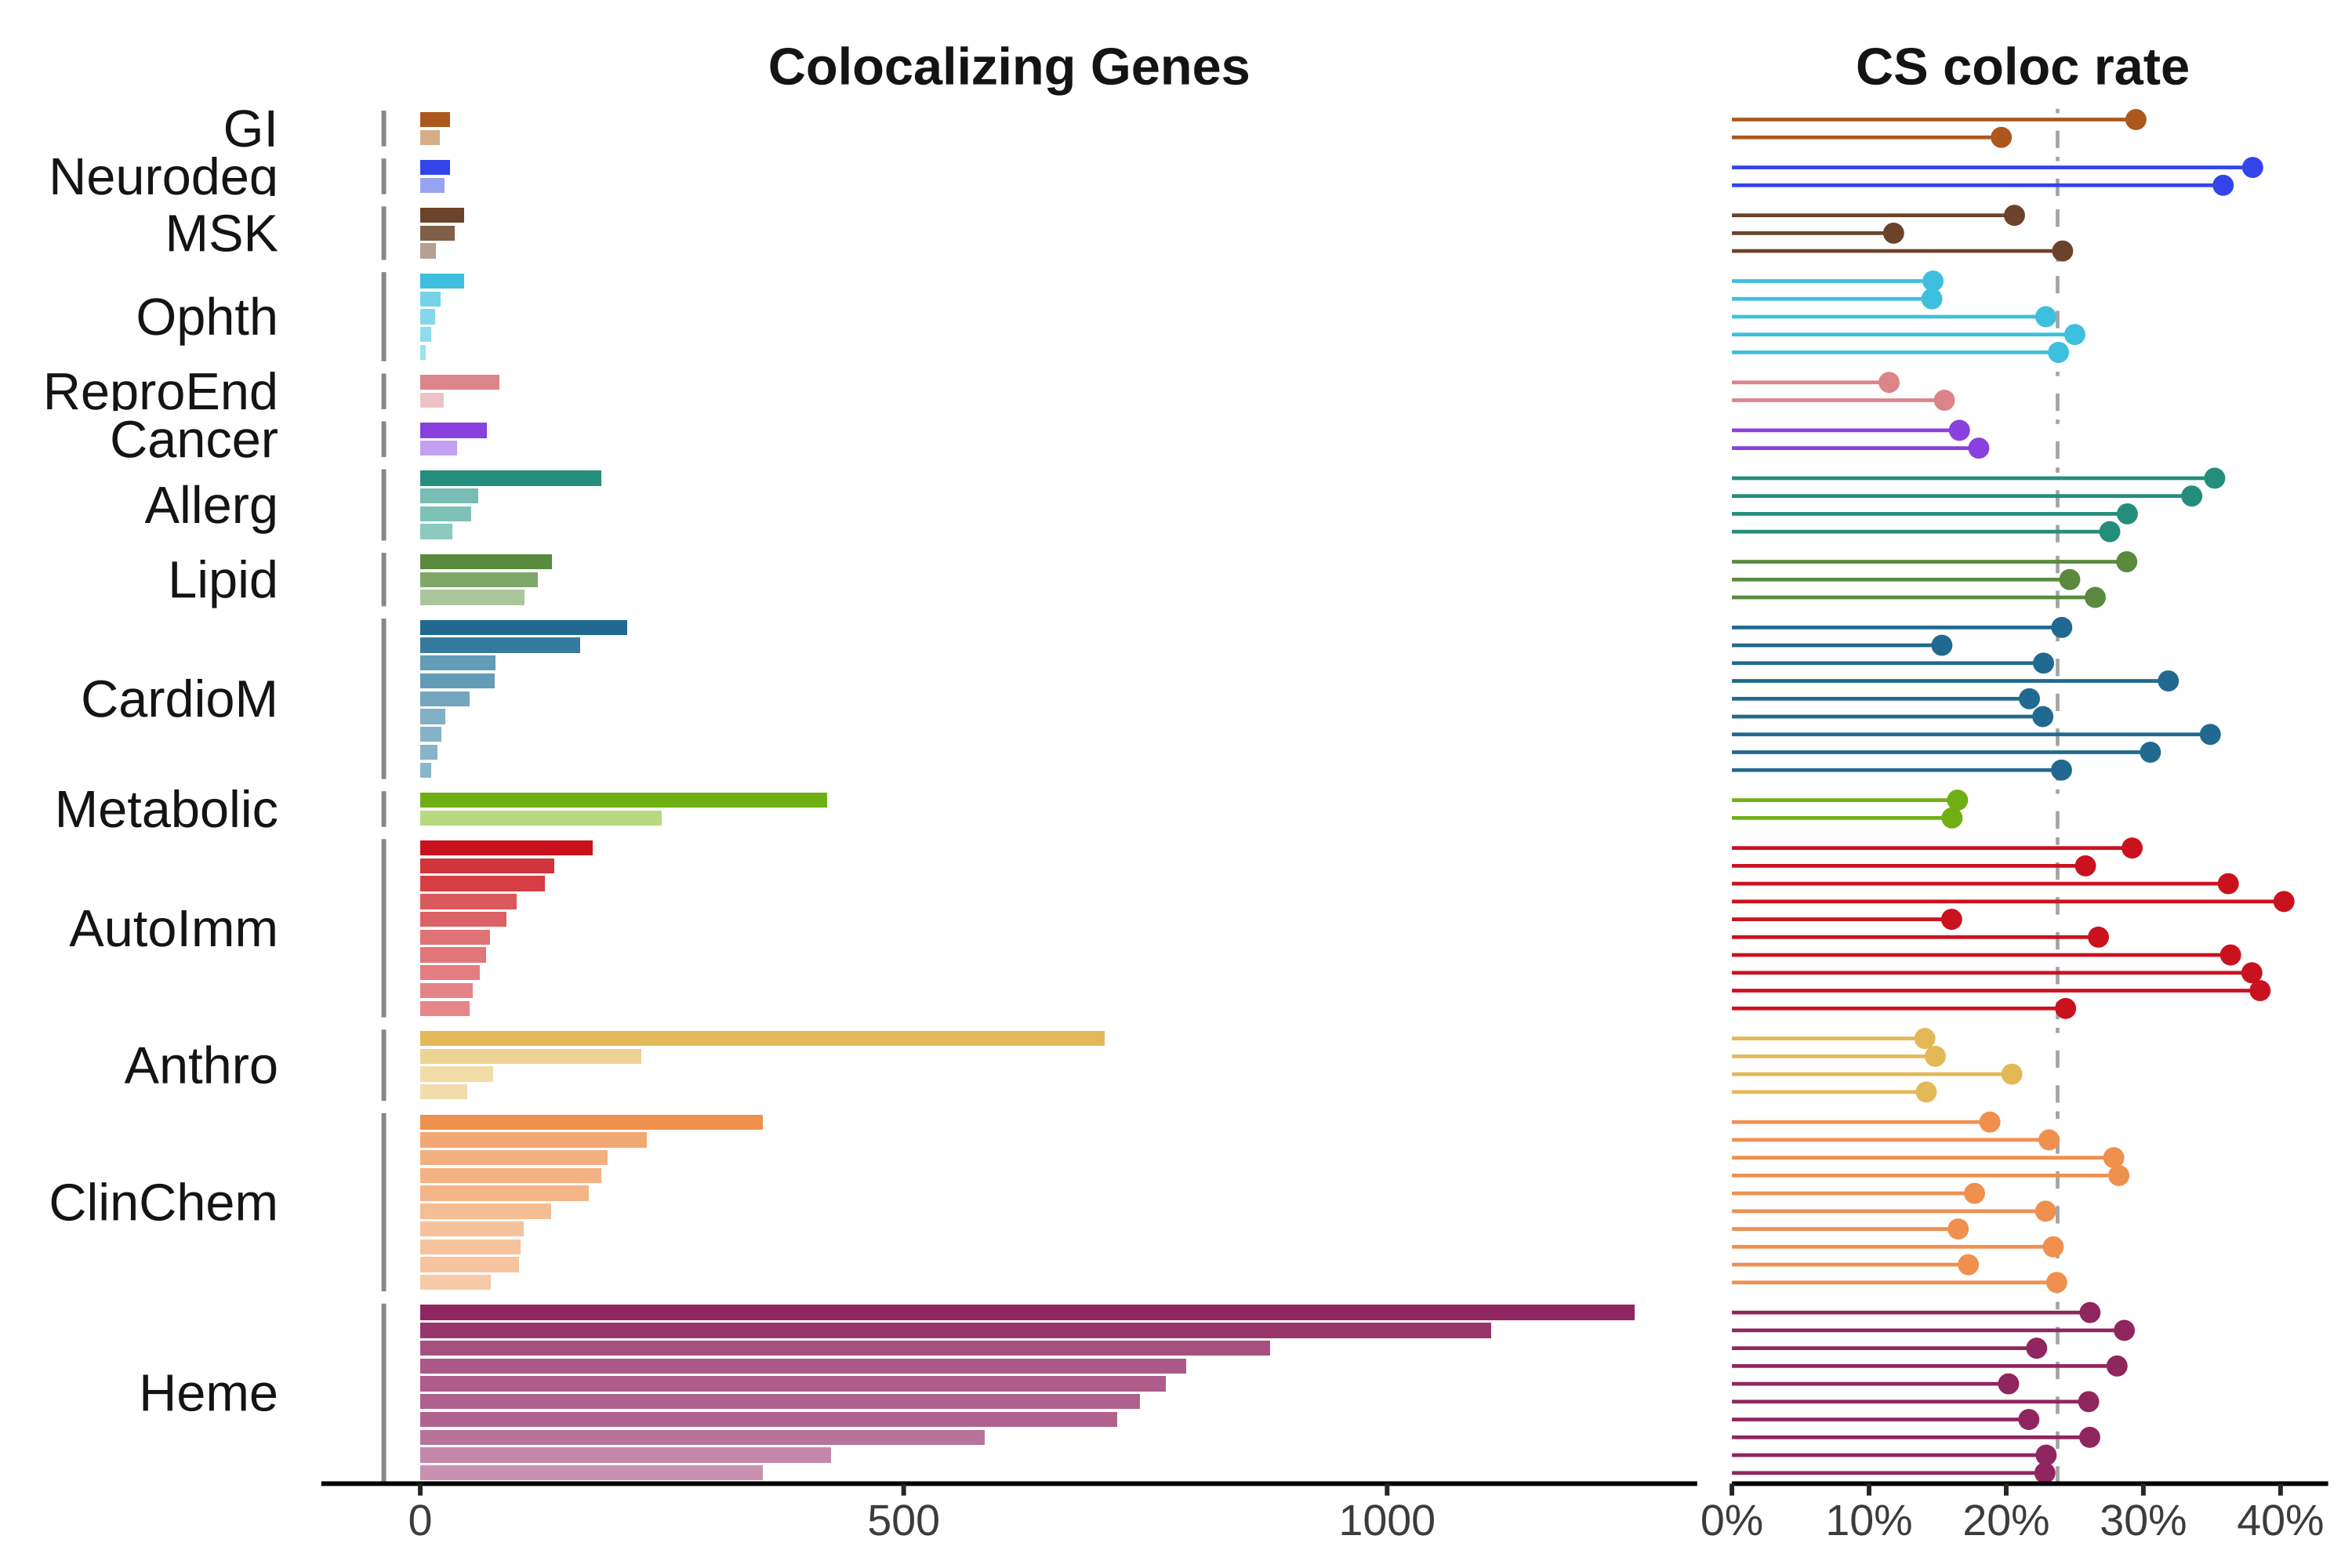

In [2]:
coloc_plot <- coloc_by_trait() %>%
  filter(trait_category != "neuropsychiatric", trait_category != "renal_urological") %>%
  filter(count > 5) %>%
  group_by(trait_category) %>%
  arrange(desc(count)) %>%
  filter(row_number() < 11) %>%
  build_plot() +
  theme(axis.text.x = element_text(size = 10))

saveRDS(coloc_plot, file.path(OBJ_DIR, "A.rds"))
message("Panel A built.")

coloc_plot


### Panel A (labelled variant) — same data and layout as panelA.R, plus a short label on every trait, right-aligned into the dead space to the right of the bars. Smaller than build_plot()'s default label size: 70 rows share the panel height, so the type has to fit a ~9pt row pitch. Feeds Figure4_labeled.pdf; Figure4.pdf still uses the plain A.rds.

The same panel with `build_plot(label_top = Inf)`, which gives **every** trait a short label in the empty space to the right of the bars. All the labels are right-aligned at one x, in a column reserved by extending the count axis past the longest bar, so they line up and no bar reaches a label; the room needed is estimated per label from its character count. Because the axis is extended, this panel's x-axis breaks differ from the plain Panel A's. Label text comes from `trait_label()`: the `TRAIT_SHORTHAND` override if there is one (matched case-insensitively, because the coloc table has changed the case of its trait names between releases), else the upstream name tidied. This feeds `Figure4_labeled.pdf`; `Figure4.pdf` still uses the unlabelled panel.

*Inputs: coloc_gene, coloc_rate*


Panel A (labelled) built.



Shown at the row height Panel A gets in the assembled figure.



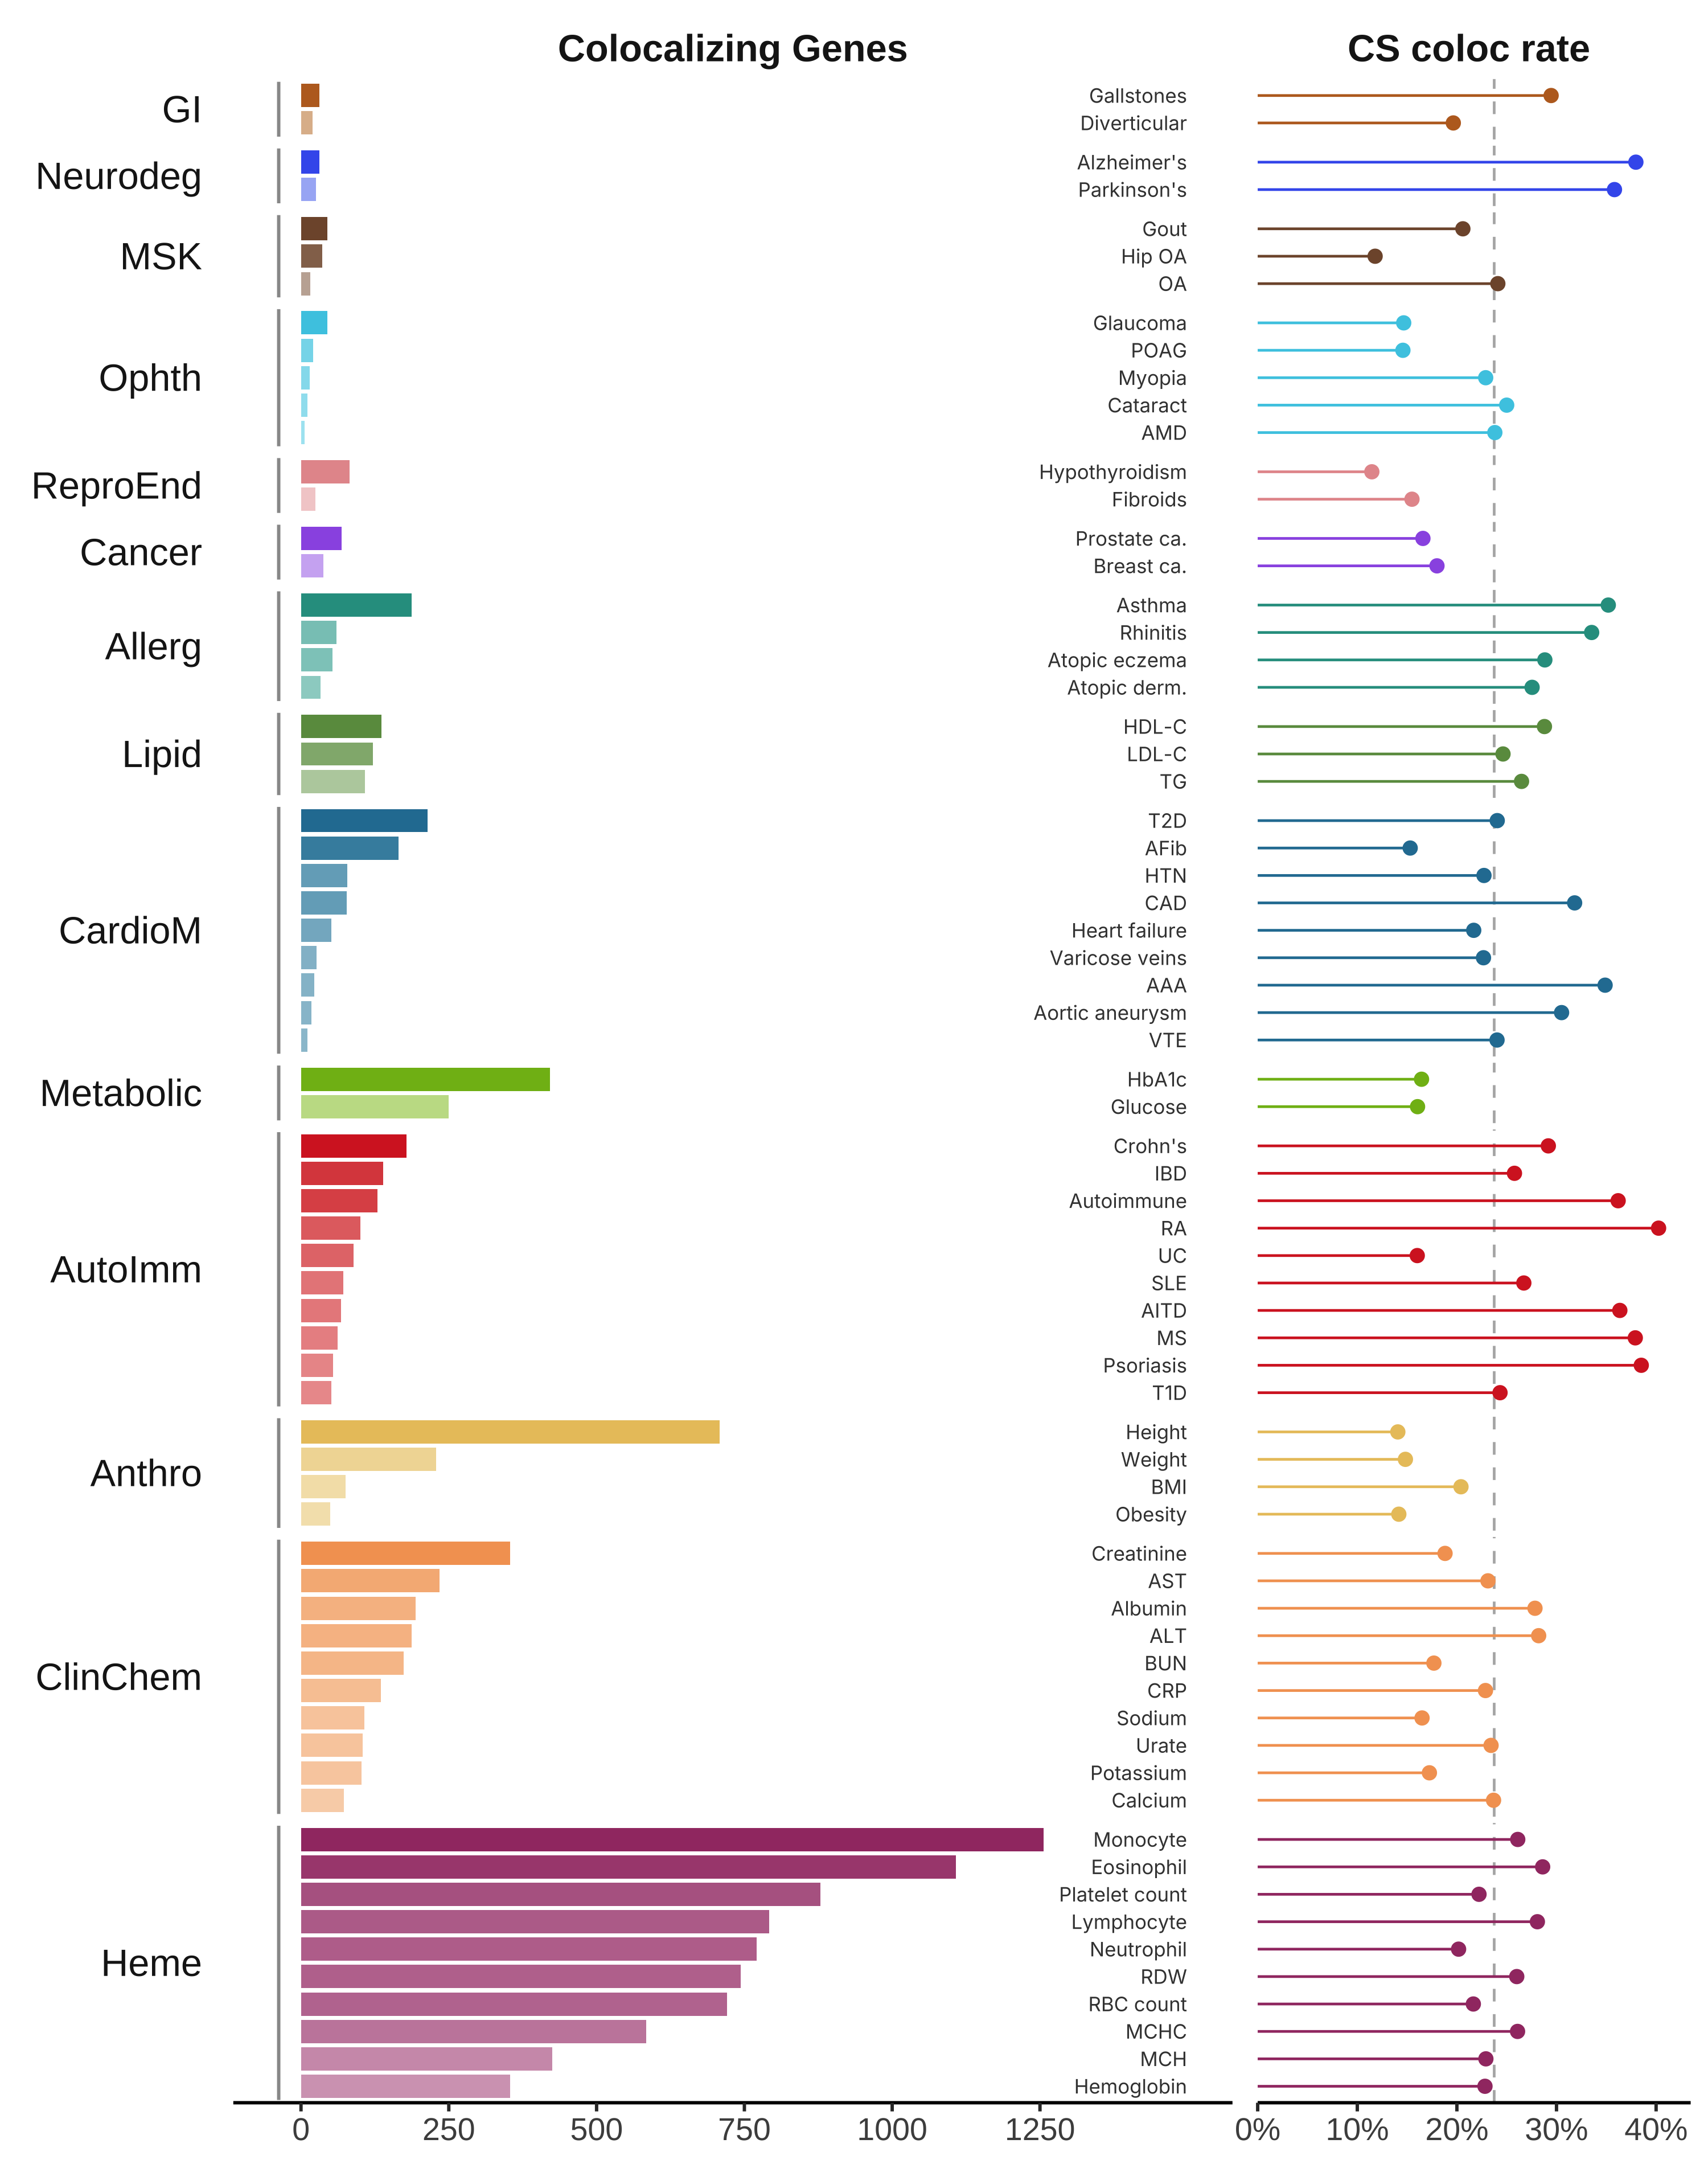

In [3]:
coloc_plot <- coloc_by_trait() %>%
  filter(trait_category != "neuropsychiatric", trait_category != "renal_urological") %>%
  filter(count > 5) %>%
  group_by(trait_category) %>%
  arrange(desc(count)) %>%
  filter(row_number() < 11) %>%
  build_plot(label_top = Inf, label_size = 2.2) +
  theme(axis.text.x = element_text(size = 10))

saveRDS(coloc_plot, file.path(OBJ_DIR, "A_labeled.rds"))
message("Panel A (labelled) built.")

old <- options(repr.plot.height = 9.5)
print(coloc_plot)
options(old)
message("Shown at the row height Panel A gets in the assembled figure.")


### Panel B — R^2 increase (%) contributed by rare variants

Histogram of the R² increase (%) that rare variants add to TWAS, computed as the difference in adjusted R² between allele-frequency thresholds 0 and 0.01 for genes with a significant fit — how much predictive signal rare variants contribute. Note the axis is truncated with `xlim(-20, 40)`, so genes whose R² increase falls outside that window are dropped from the histogram rather than shown at the edge.

*Inputs: r2_twas*


Panel B built.



`stat_bin()` using `bins = 30`. Pick better value with `binwidth`.


Warning message:
“Removed 148 rows containing non-finite outside the scale range (`stat_bin()`).”


Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_bar()`).”


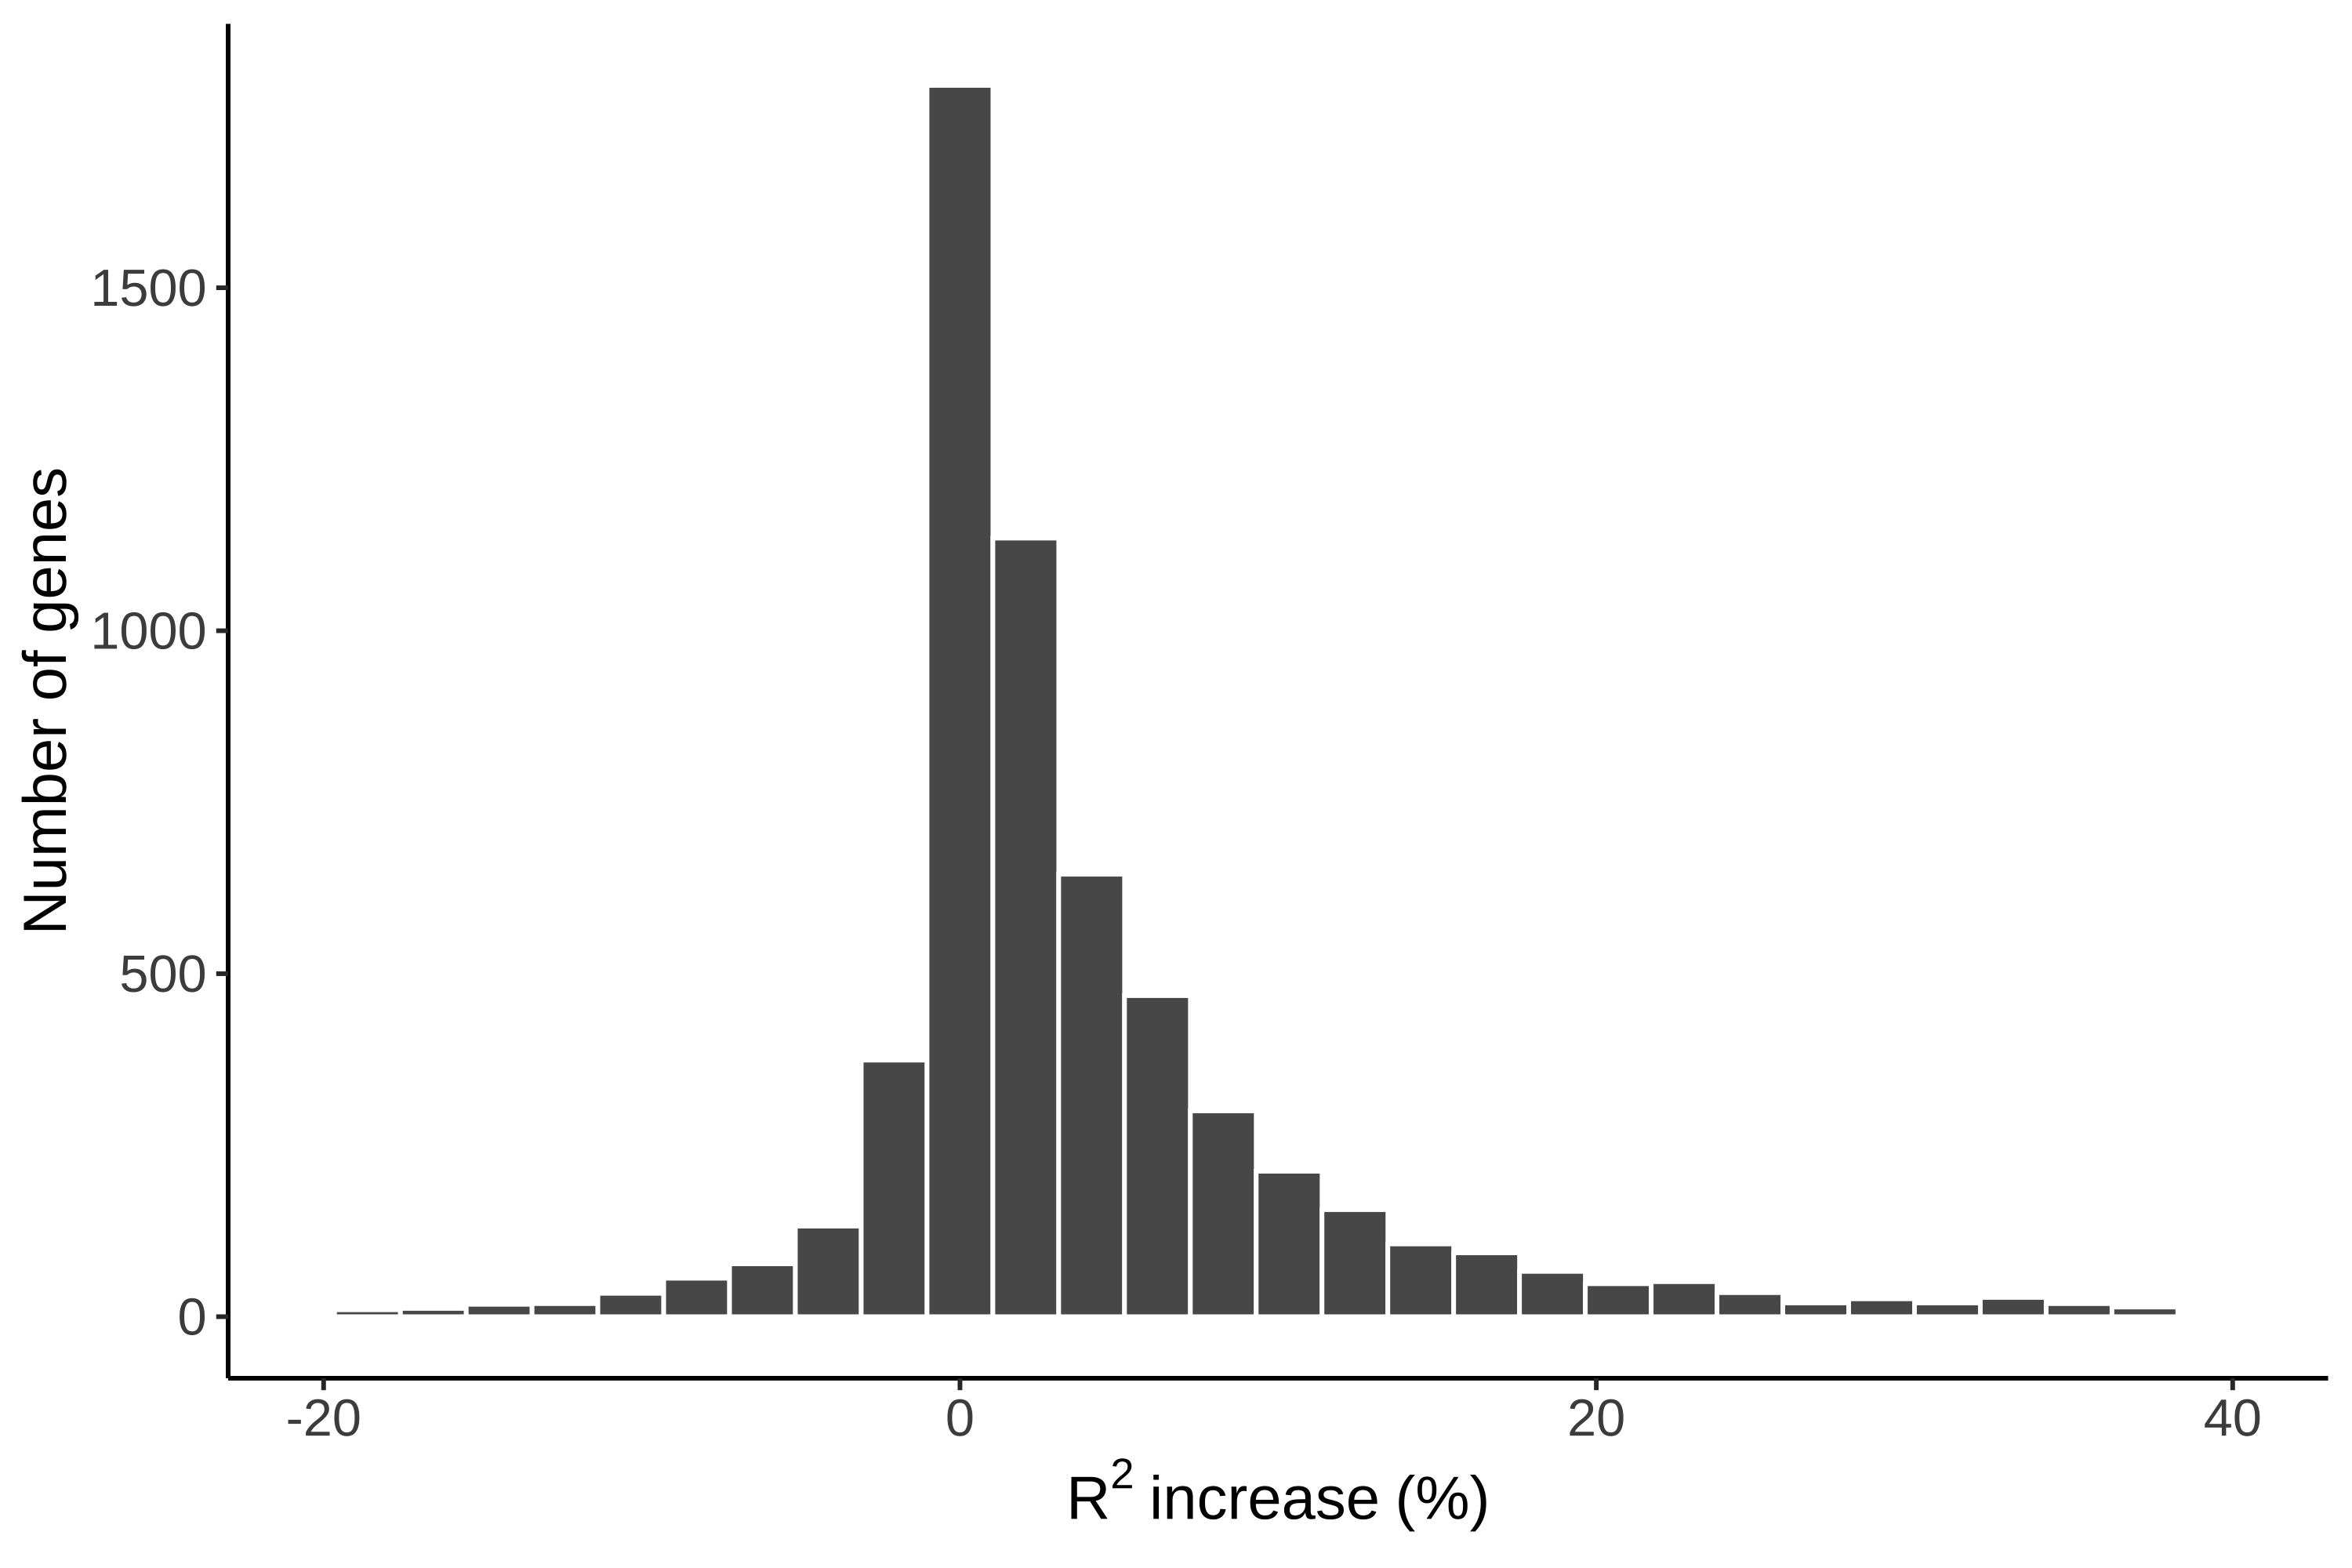

In [4]:
R2_combined <- read_any(input_path("r2_twas")) %>%
  mutate(H2_upper = (SE * 1.96) + H2, adj_R2 = r.squared / H2) %>%
  filter(Pval < 1e-5) %>%
  select(phenotype_id, AF_threshold, adj_R2, H2, Pval) %>%
  pivot_wider(names_from = AF_threshold, values_from = adj_R2) %>%
  mutate(difference = (`0` - `0.01`))

R2_dist <- R2_combined %>%
  ggplot(aes(x = 100 * difference)) +
  geom_histogram(color = "white") +
  ylab("Number of genes") +
  xlim(-20, 40) +
  theme_classic() +
  theme(axis.text = element_text(size = 12), axis.title = element_text(size = 14)) +
  labs(x = expression(R^2 ~ increase ~ "(%)"))

saveRDS(R2_dist, file.path(OBJ_DIR, "B.rds"))
message("Panel B built.")

R2_dist


### Panel C — conditional-TWAS QQ, colocalized vs matched non-colocalized (blood)

Common and rare conditional-TWAS QQ plots over nine blood traits, comparing colocalized genes against **MatchIt propensity-matched** non-colocalized genes ("Null") — an inflation test that controls for expression, selection, rare-variant count and LD.

*Inputs: conditional_twas*


Panel C built.



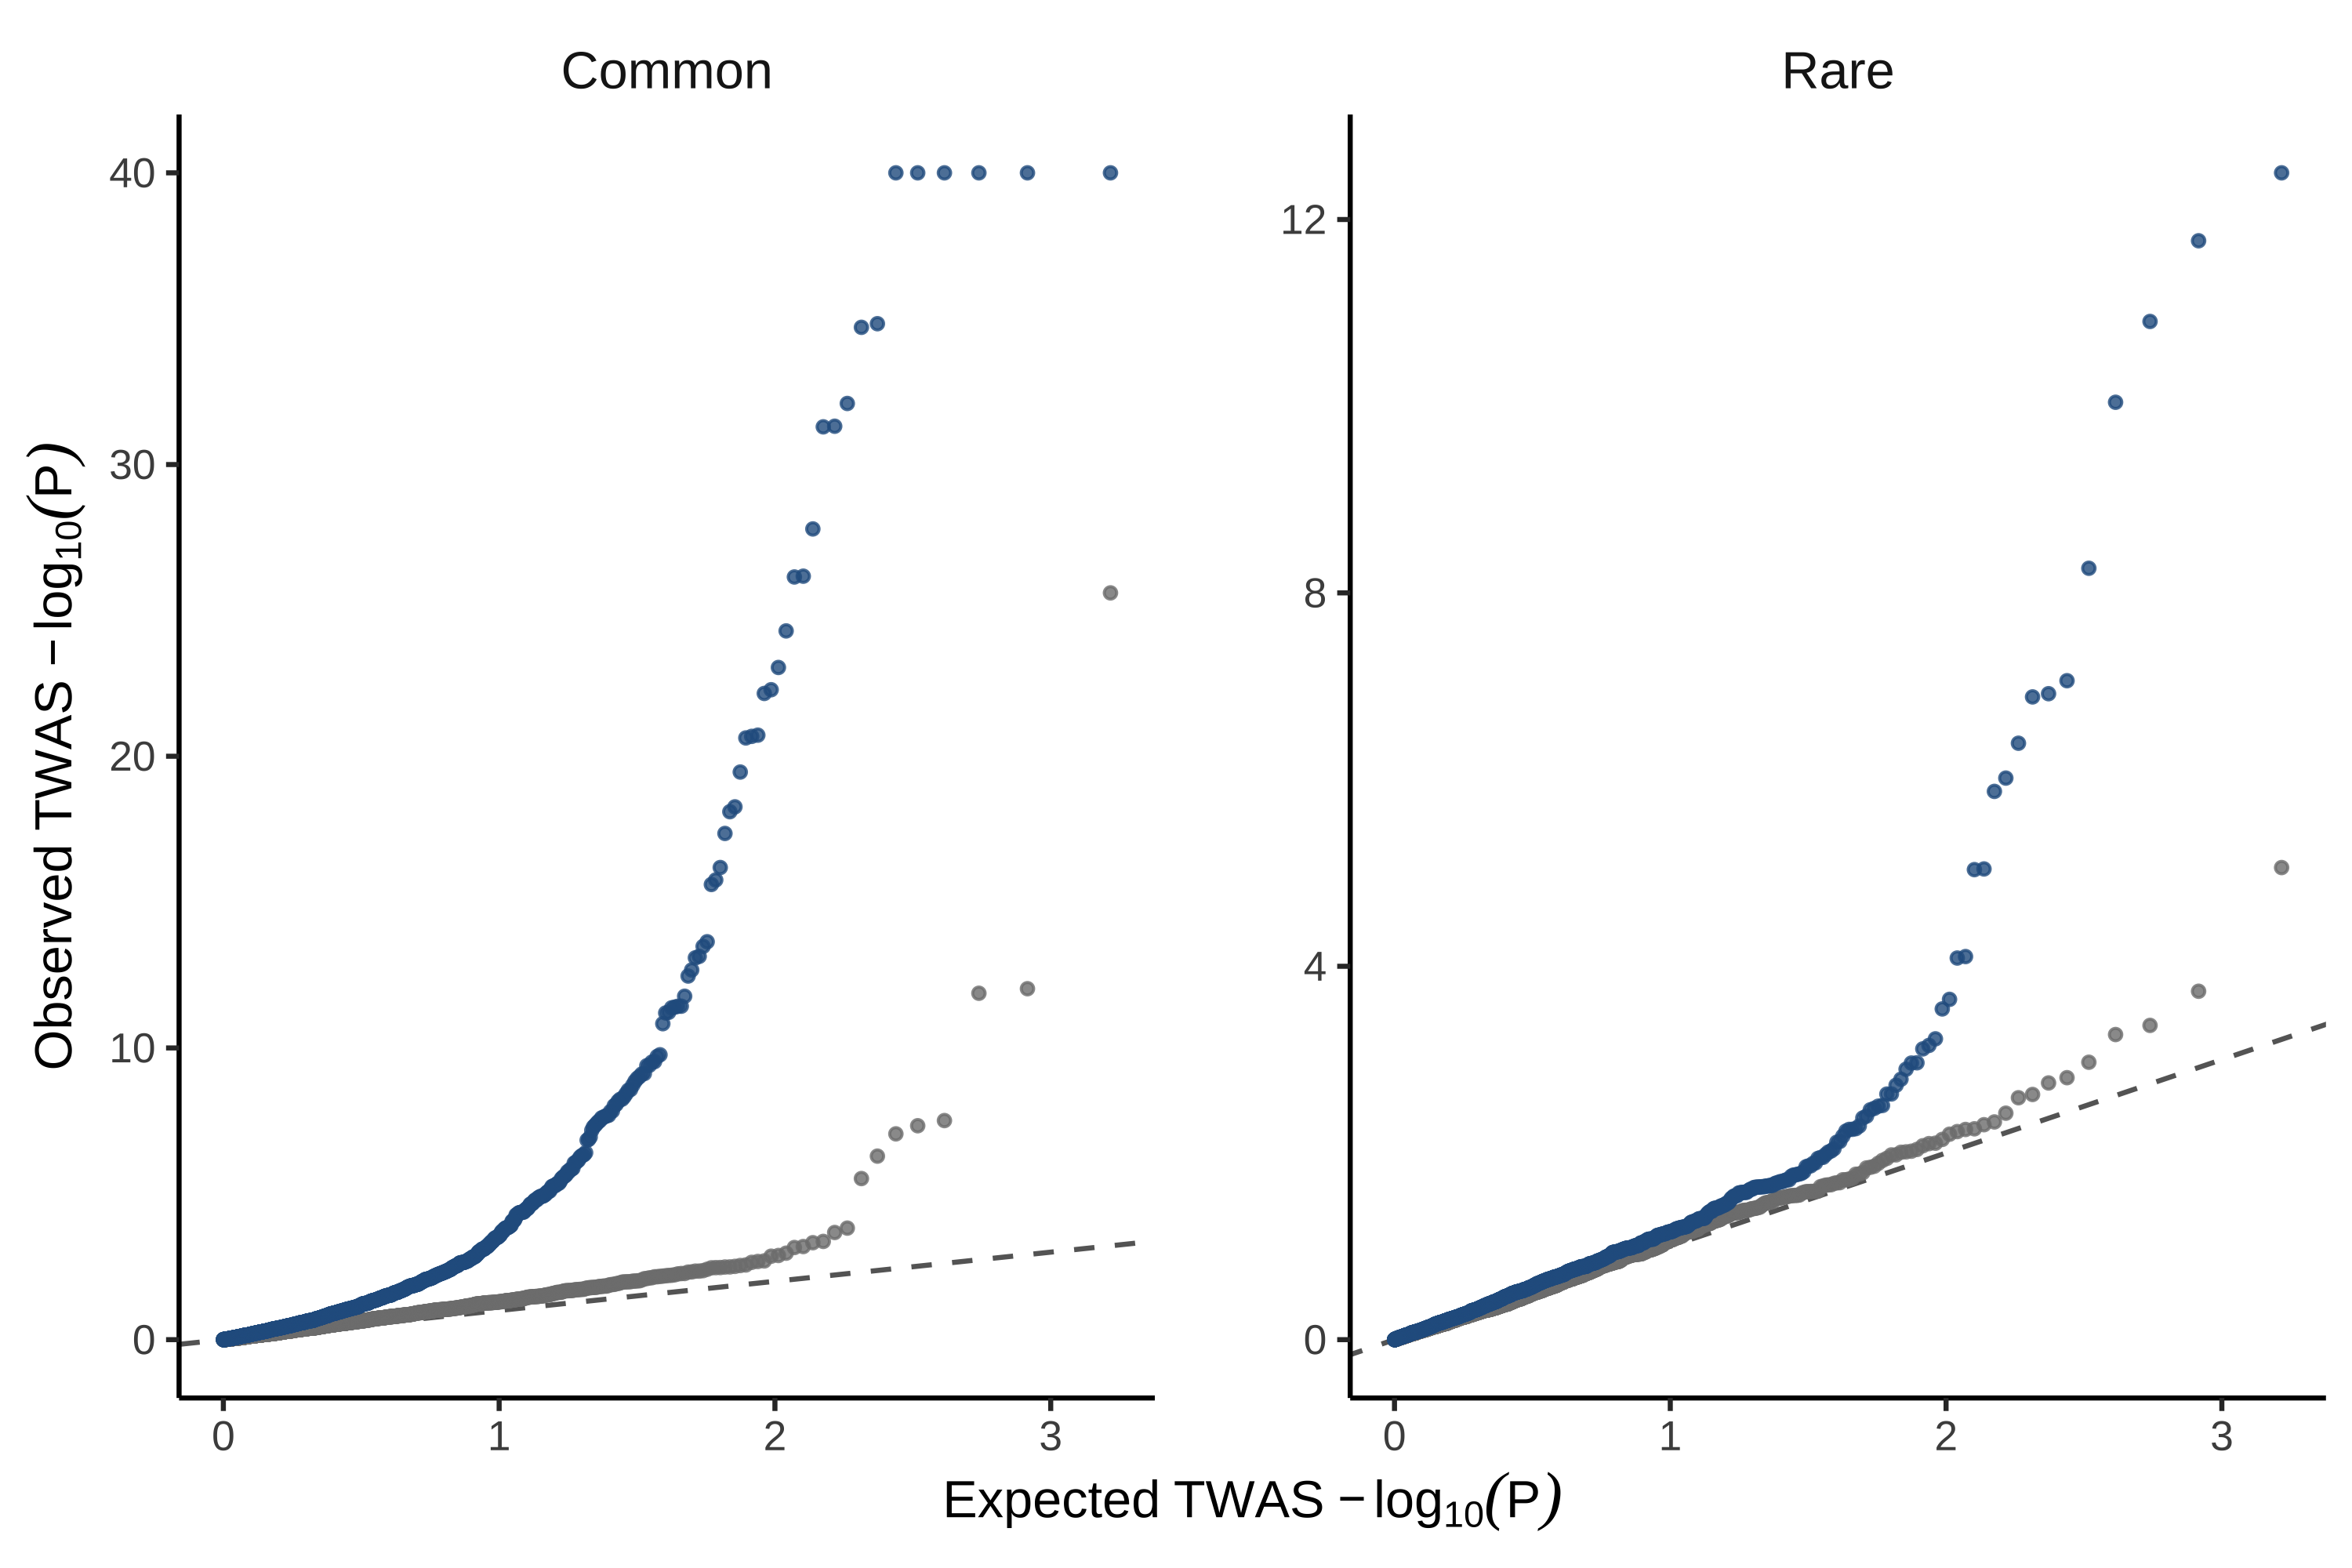

In [5]:
qq_blood <- calculate_qq_data(qq_match_source(), traits = BLOOD_TRAITS)

p_blood_qq <- qq_blood %>%
  mutate(group = case_when(str_detect(group, "Matched") ~ "Null", TRUE ~ group)) %>%
  plot_qq() +
  theme(legend.position = "none")

saveRDS(p_blood_qq, file.path(OBJ_DIR, "C.rds"))
message("Panel C built.")

p_blood_qq


### Panel D — gene-set enrichment odds-ratio forest (rare vs common TWAS signal)

Odds-ratio forest (logistic regression) for the enrichment of rare vs. common conditional-TWAS signal across four gene-set outcomes — Mendelian (any), Mendelian (immune/hematological), druggable, and approved drug target. Both continuous and binary predictor sets are fit; the panel plots the continuous rare/common terms (see `Fig4/NOTES.md`).

*Inputs: conditional_twas, clingen, drug_interactions*


Warning message:
“A numeric `legend.position` argument in `theme()` was deprecated in ggplot2
3.5.0.
ℹ Please use the `legend.position.inside` argument of `theme()` instead.”


Panel D built.



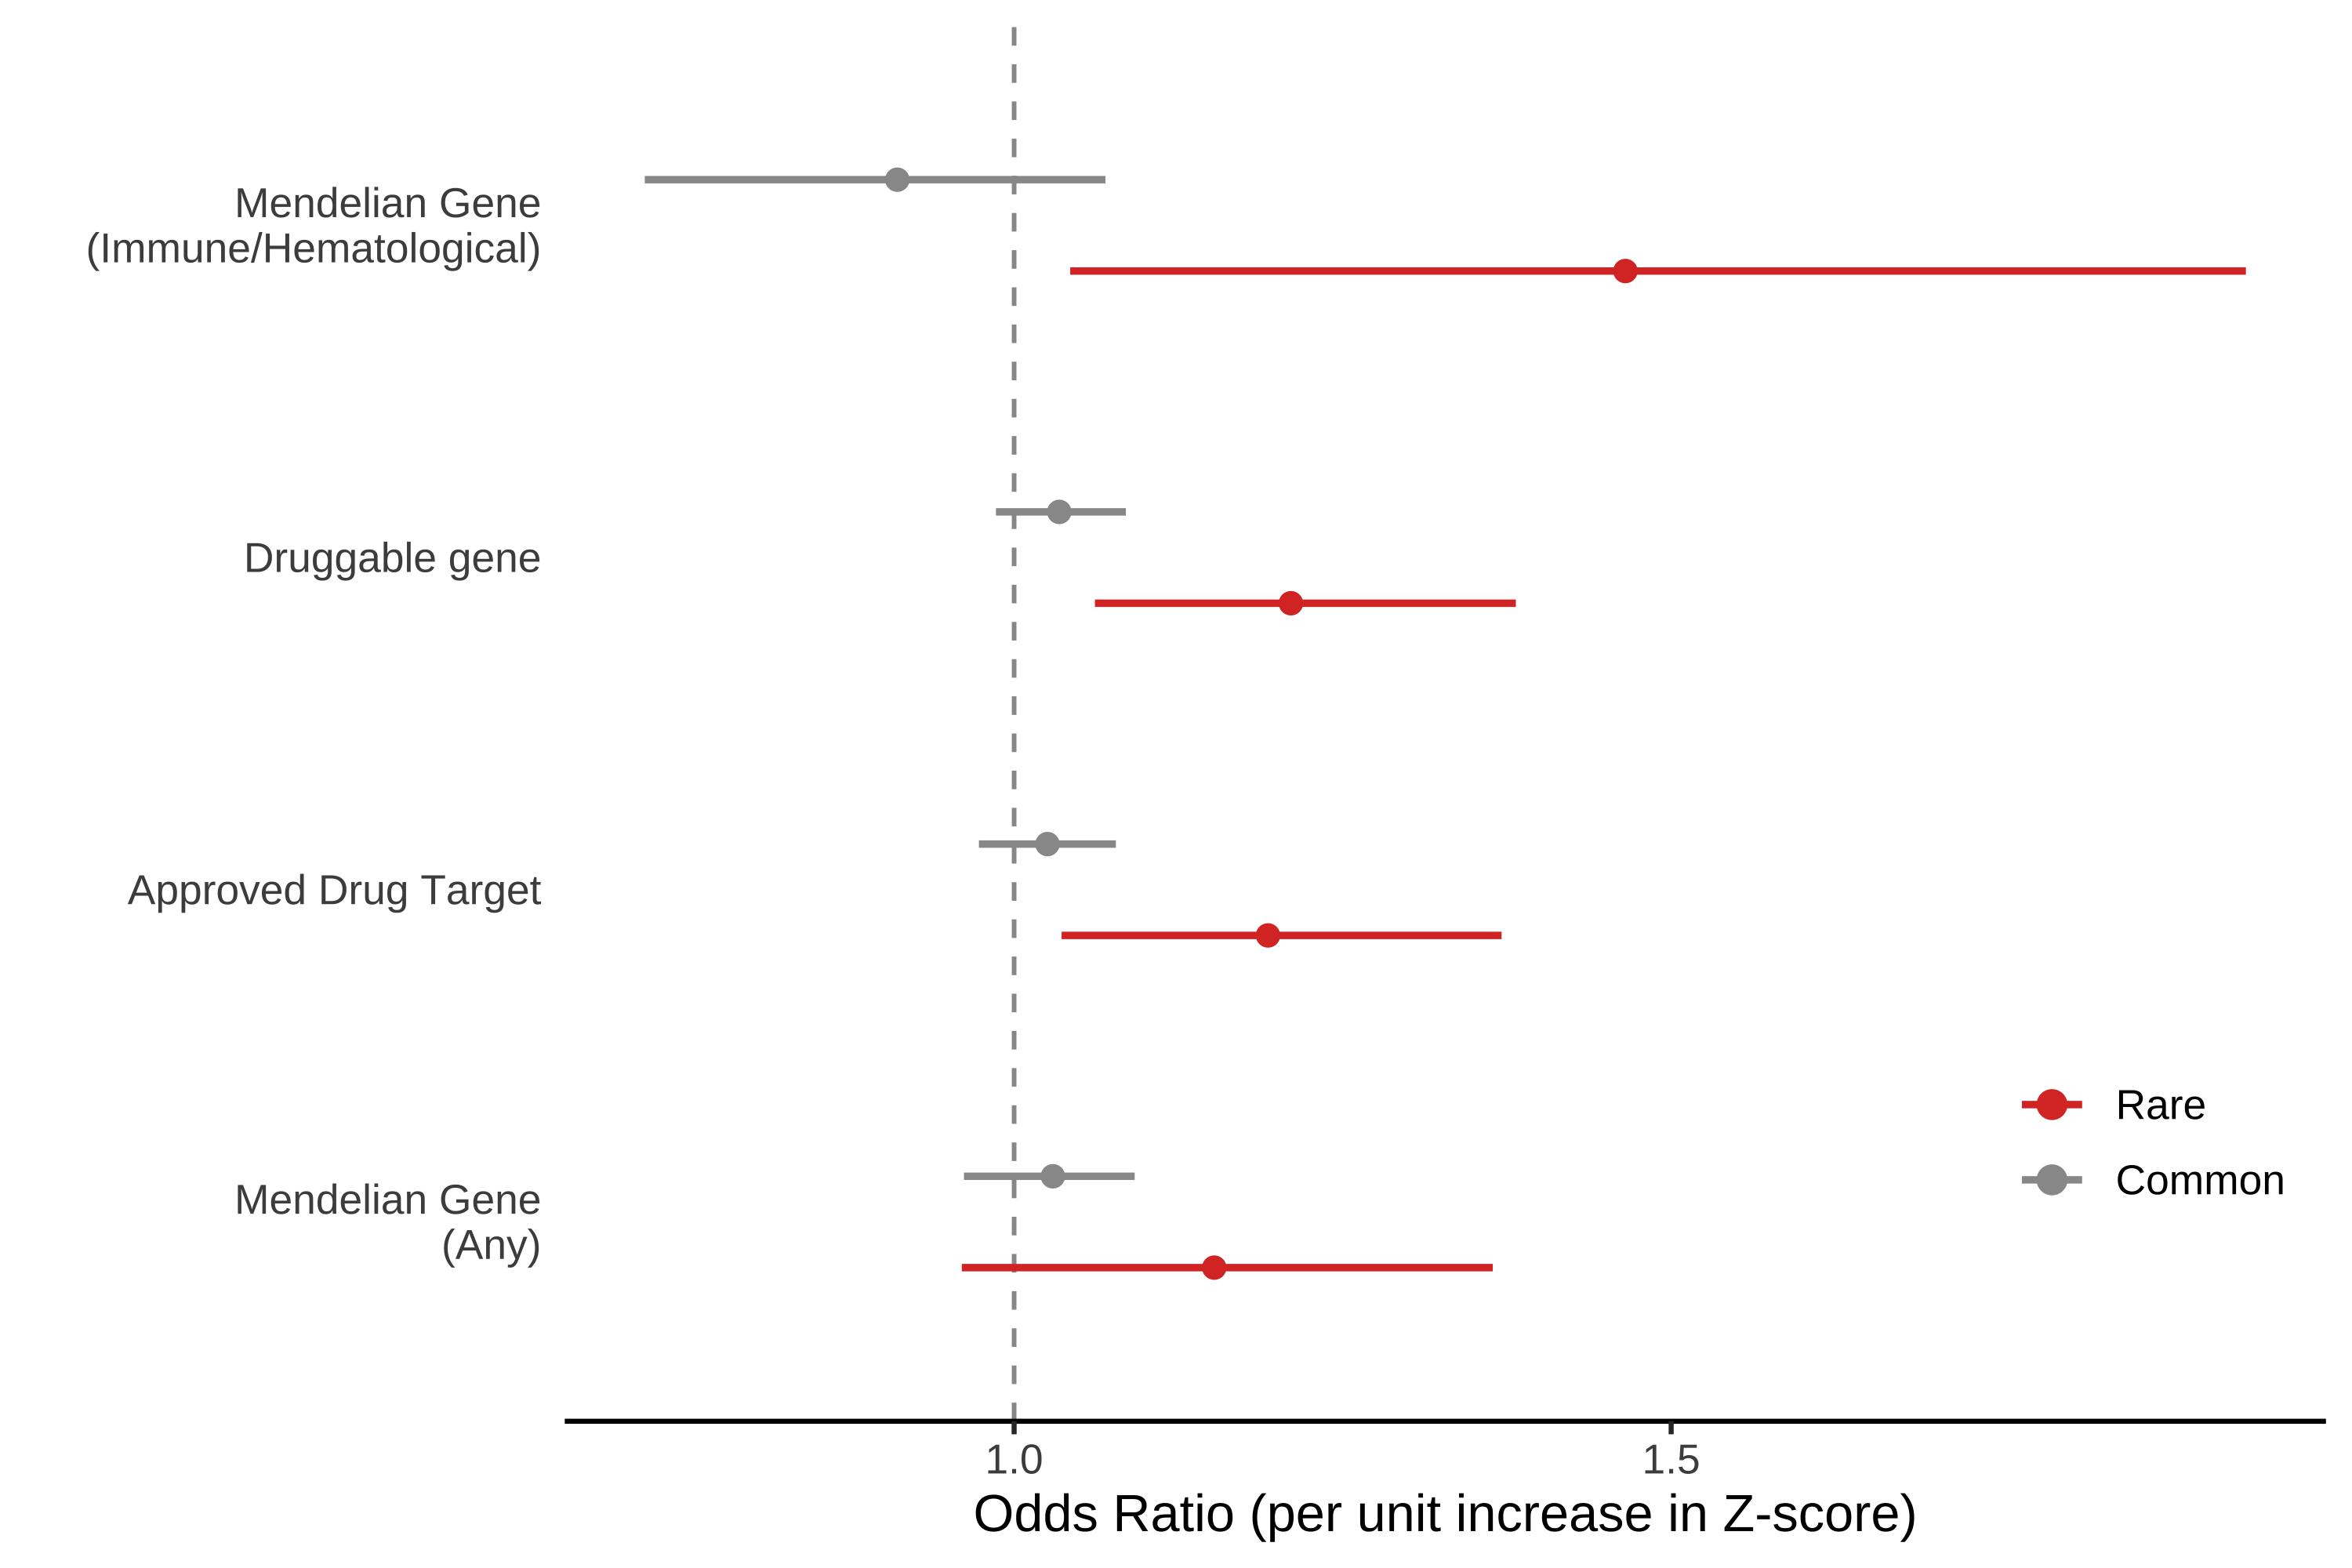

In [6]:
gtd <- gene_twas_data()

# Every outcome x predictor-set combination is fit; the panel plots only the
# continuous max_rare / max_common terms. The binary-predictor fits are computed
# but not plotted (see NOTES.md).
enrichment_results <- tidyr::expand_grid(outcome = names(ENRICH_OUTCOMES),
                                         model   = names(ENRICH_PREDICTORS)) %>%
  mutate(res = map2(outcome, model, ~ fit_enrich(.x, ENRICH_PREDICTORS[[.y]], gtd))) %>%
  unnest(res) %>%
  mutate(type = ENRICH_OUTCOMES[outcome]) %>%
  relocate(type, model)

plot_df <- enrichment_results %>%
  filter(term %in% c("max_rare", "max_common")) %>%
  select(type, model, term, OR = estimate, conf.low, conf.high, p.value) %>%
  mutate(term = str_remove_all(term, "max_|ever_|TRUE"),
         term = recode(term, rare = "Rare", common = "Common"),
         term = factor(term, levels = c("Rare", "Common")),
         type = factor(type, levels = c("Mendelian Gene\n(Any)",
                                        "Mendelian Gene\n(Immune/Hematological)",
                                        "Druggable gene", "Approved Drug Target")))

pal <- c(Rare = as.character(paletteer_d("futurevisions::mars"))[1], Common = "grey60")
p <- ggplot(plot_df, aes(OR, reorder(type, OR), colour = term)) +
  geom_vline(xintercept = 1, linetype = "dashed", colour = "grey60") +
  geom_pointrange(aes(xmin = conf.low, xmax = conf.high),
                  position = position_dodge(width = .55), linewidth = .8, fatten = 2.6) +
  scale_colour_manual(values = pal, name = NULL) +
  theme_classic(base_size = 12) +
  theme(axis.line.y = element_blank(), axis.ticks.y = element_blank(),
        strip.background = element_blank(), strip.text = element_text(face = "bold"),
        legend.position = c(0.9, 0.2), panel.spacing = unit(1.4, "lines")) +
  xlab("Odds Ratio (per unit increase in Z-score)") + ylab("")

saveRDS(p, file.path(OBJ_DIR, "D.rds"))
message("Panel D built.")

p


## Assemble the figure

Loads the cached panel objects from `Fig4/objects/` and composes them with patchwork into the final figure. Panel **tagging happens here and only here**. Writes the PDF plus a PNG preview, and renders the assembled figure inline.


`stat_bin()` using `bins = 30`. Pick better value with `binwidth`.


Warning message:
“Removed 148 rows containing non-finite outside the scale range (`stat_bin()`).”


Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_bar()`).”


`stat_bin()` using `bins = 30`. Pick better value with `binwidth`.


Warning message:
“Removed 148 rows containing non-finite outside the scale range (`stat_bin()`).”


Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_bar()`).”


... (7 outputs left out)

Assembled: fig4/Figure4_labeled.pdf and Figure4_labeled.png



`stat_bin()` using `bins = 30`. Pick better value with `binwidth`.


Warning message:
“Removed 148 rows containing non-finite outside the scale range (`stat_bin()`).”


Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_bar()`).”


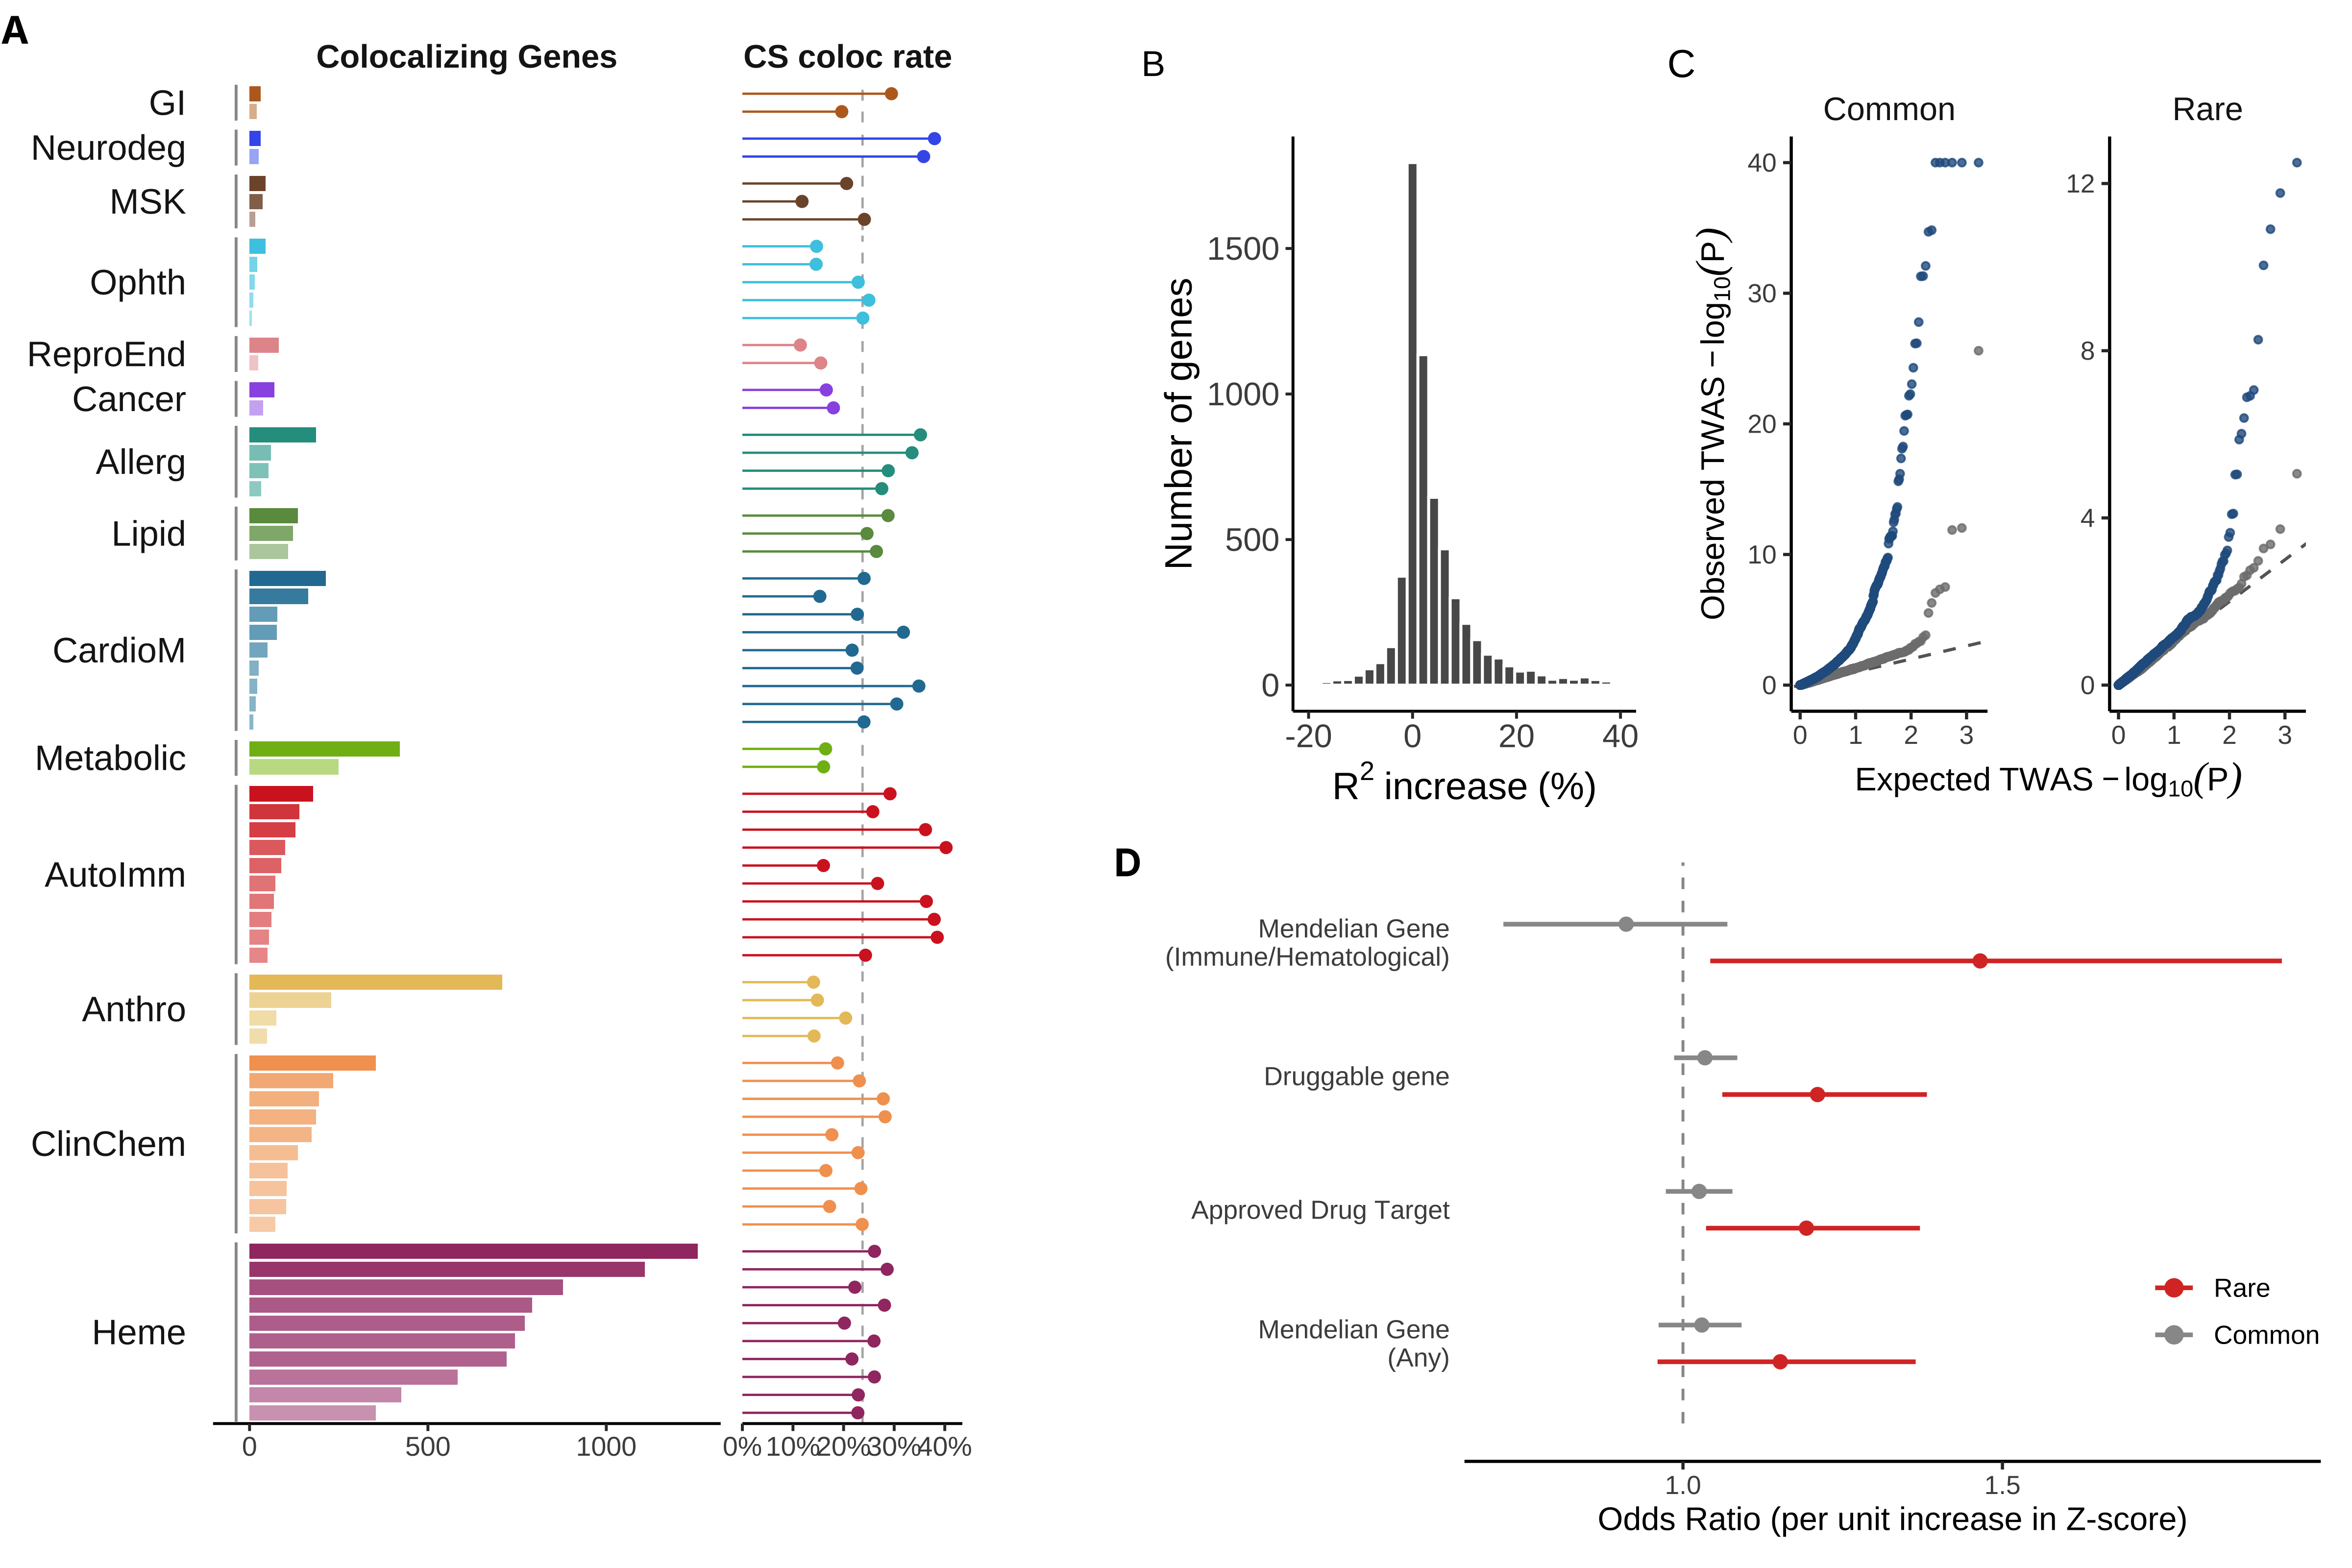

In [7]:
P <- setNames(lapply(LETTERS[1:4],
                     function(x) readRDS(file.path(OBJ_DIR, paste0(x, ".rds")))),
              LETTERS[1:4])

compose_fig4 <- function(panel_a) {
  top_row <- ((P$B + labs(tag = "B")) | (P$C + labs(tag = "C"))) +
    plot_layout(widths = c(0.8, 1.2))
  top_row <- wrap_elements(full = top_row)   # isolate B/C from D's axis-label spacing

  right_side <- top_row / (P$D + labs(tag = "D")) +
    plot_layout(heights = c(1, 0.75))

  ((panel_a + labs(tag = "A") +
      theme(plot.margin = margin(r = 55, unit = "pt"),
            strip.text.y.left = element_text(angle = 0, hjust = 1, size = 13))) |
     right_side) +
    plot_layout(widths = c(7, 8)) &
    theme(plot.tag = element_text(size = SZ_TAG, face = "bold", family = FONT),
          plot.tag.position = c(0, 1))
}

save_fig4 <- function(fig, base) {
  ggsave(file.path(OUTDIR, paste0(base, ".pdf")), fig, width = 15, height = 10, dpi = DPI)
  showtext_opts(dpi = 100)
  ggsave(file.path(OUTDIR, paste0(base, ".png")), fig, width = 15, height = 10, dpi = 100)
  showtext_opts(dpi = DPI)
  message("Assembled: ", file.path(OUTDIR, paste0(base, ".pdf")), " and ", base, ".png")
}

Fig4 <- compose_fig4(P$A)
save_fig4(Fig4, "Figure4")

a_labeled <- file.path(OBJ_DIR, "A_labeled.rds")
if (file.exists(a_labeled)) {
  Fig4_labeled <- compose_fig4(readRDS(a_labeled))
  save_fig4(Fig4_labeled, "Figure4_labeled")
} else {
  message("Skipped Figure4_labeled: ", a_labeled, " not built ",
          "(run fig4/panels/panelA_labeled.R).")
}

options(repr.plot.width = 12.0, repr.plot.height = 8.0)
Fig4
